<a href="https://colab.research.google.com/github/roser740/Data-Analytics/blob/main/TASQUES%20S13/ETL_contaminacio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ANÀLISI DE LA QUALITAT DE L'AIRE A LA PLANA DE VIC**

# **💢 ETL (EXTRACT, TRANSFORM, LOAD) DE LES DADES DE CONTAMINACIÓ**

# **📚 Llibreries**

In [71]:

import pandas as pd # llibreria per gestionar dataframes
import numpy as np # llibreria per computació numèrica i científica
import codecs # mòdul per codificar i descodificar dades en diferents formats
import seaborn as sns # llibreria de visualització de dades
import matplotlib.pyplot as plt # llibreria per fer gràfiques

from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

# **⭕ Funcions generals**

In [72]:
def mostrar_dataframe(df, títol):
#Presenta les dades en format tabular amb el títol indicat

    # Mostrem títol
    print("\n" + "="*100)
    print(títol)
    print("="*100)
    # La funció display mostra les dades del dataframe en format taula.
    # Utilitzem la propietat style per amagar la columna de l'índex.
    display(df)

##🟢**Extract: obtenir dades de diferents fonts**

In [73]:
url = "https://github.com/roser740/Data-Analytics/raw/main/TASQUES%20S13/DADES/"

In [74]:
df_vic = pd.read_csv(url+"Punts_aut_Vic.csv", sep = ",", header=0, encoding='latin1', low_memory = False)
df_manlleu = pd.read_csv(url+"Punts_aut_Manlleu.csv", sep = ",", header=0, encoding='latin1', low_memory = False)
df_tona= pd.read_csv(url+"Punts_aut_Tona.csv", sep = ",", header=0, encoding='latin1', low_memory = False)
df_manresa = pd.read_csv(url+"Punts_aut_Manresa.csv", sep = ",", header=0, encoding='latin1', low_memory = False)
df_eixample = pd.read_csv(url+"Punts_aut_Eixample.csv", sep = ",", header=0, encoding='latin1', low_memory = False)
df = pd.concat([df_vic, df_manlleu, df_tona, df_manresa, df_eixample], ignore_index=True)
df.head(10)

,CODI EOI,NOM ESTACIO,DATA,MAGNITUD,CONTAMINANT,UNITATS,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,...,19h,20h,21h,22h,23h,24h,ALTITUD,LATITUD,LONGITUD,GeoreferÃ¨ncia
0,8298008,Vic,10/11/2026,8,NO2,ug/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
1,8298008,Vic,10/11/2026,12,NOX,Âµg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
2,8298008,Vic,10/11/2026,14,O3,ug/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
3,8298008,Vic,10/11/2026,7,NO,ug/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
4,8298008,Vic,10/11/2026,10,PM10,Âµg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
5,8298008,Vic,09/11/2026,12,NOX,Âµg/m3,background,suburban,8298,Vic,...,29,43,50,29,28,22,498,"41,93501","2,2400014",NaN
6,8298008,Vic,09/11/2026,8,NO2,ug/m3,background,suburban,8298,Vic,...,28,39,45,27,25,19,498,"41,93501","2,2400014",NaN
7,8298008,Vic,09/11/2026,7,NO,ug/m3,background,suburban,8298,Vic,...,1,3,3,2,2,2,498,"41,93501","2,2400014",NaN
8,8298008,Vic,09/11/2026,14,O3,ug/m3,background,suburban,8298,Vic,...,17,5,4,3,4,10,498,"41,93501","2,2400014",NaN
9,8298008,Vic,09/11/2026,10,PM10,Âµg/m3,background,suburban,8298,Vic,...,9,9,11,10,10,9,498,"41,93501","2,2400014",NaN


##🟢 **Exploració inicial del dataset**

### **1. Obtenir les dimensions del dataframe**

In [75]:

print ("Número de files: ", df.shape[0])
print ("Número de columnes: ", df.shape[1])

Número de files:  241845
Número de columnes:  40


### **2. Tipus de dades**

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241845 entries, 0 to 241844
Data columns (total 40 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   CODI EOI        241845 non-null  int64 
 1   NOM ESTACIO     241845 non-null  object
 2   DATA            241845 non-null  object
 3   MAGNITUD        241845 non-null  int64 
 4   CONTAMINANT     241845 non-null  object
 5   UNITATS         241845 non-null  object
 6   TIPUS ESTACIO   241845 non-null  object
 7   AREA URBANA     241845 non-null  object
 8   CODI INE        241845 non-null  int64 
 9   MUNICIPI        241845 non-null  object
 10  CODI COMARCA    241845 non-null  int64 
 11  NOM COMARCA     241845 non-null  object
 12  01h             231982 non-null  object
 13  02h             231043 non-null  object
 14  03h             232083 non-null  object
 15  04h             231843 non-null  object
 16  05h             232543 non-null  object
 17  06h             232721 non-nu

### **3. Detecció de duplicats**

In [77]:
#Obtenim una llista de valors booleans on les files duplicades contenen valor True(1) i les altres False (0).
files_duplicades = df.duplicated(keep = False)
# Sumem els valors de la llista obtinguda.
# Com que les files duplicades tenen valor True (1) obtenim el número total de files duplicades.
print("Número de files duplicades: ", files_duplicades.sum())
# Mostrem les files duplicades ordenades per DNI.
mostrar_dataframe(df[files_duplicades].sort_values(by='CODI EOI'), "FILES DUPLICADES")

Número de files duplicades:  0

FILES DUPLICADES


,CODI EOI,NOM ESTACIO,DATA,MAGNITUD,CONTAMINANT,UNITATS,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,...,19h,20h,21h,22h,23h,24h,ALTITUD,LATITUD,LONGITUD,GeoreferÃ¨ncia


In [78]:
# Obtenim una llista de valors booleans on les files amb clau duplicada contenen valor True(1) i les altres False (0).
clau_duplicada = df.duplicated(subset=['CODI EOI', 'NOM ESTACIO','DATA','MAGNITUD'], keep= False)
# Sumem els valors de la llista per obtenir el número total de registres amb DNI duplicat.
print("Número de claus duplicades: ", clau_duplicada.sum())
# Mostrem els registres amb clau duplicada ordenats per CODI EOI
mostrar_dataframe(df[clau_duplicada].sort_values(by='CODI EOI'), "CLAUS DUPLICADES")

Número de claus duplicades:  0

CLAUS DUPLICADES


,CODI EOI,NOM ESTACIO,DATA,MAGNITUD,CONTAMINANT,UNITATS,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,...,19h,20h,21h,22h,23h,24h,ALTITUD,LATITUD,LONGITUD,GeoreferÃ¨ncia


### **4. Valors Nuls**

In [79]:
print("Valors nuls" )
print(df.isna().sum())

Valors nuls
CODI EOI              0
NOM ESTACIO           0
DATA                  0
MAGNITUD              0
CONTAMINANT           0
UNITATS               0
TIPUS ESTACIO         0
AREA URBANA           0
CODI INE              0
MUNICIPI              0
CODI COMARCA          0
NOM COMARCA           0
01h                9863
02h               10802
03h                9762
04h               10002
05h                9302
06h                9124
07h                9262
08h                9445
09h                9841
10h               10803
11h               13048
12h               15120
13h               15039
14h               13662
15h               12476
16h               11222
17h                9704
18h                8921
19h                8818
20h                8758
21h                8925
22h                9048
23h                9172
24h                9584
ALTITUD               0
LATITUD               0
LONGITUD              0
GeoreferÃ¨ncia    45931
dtype: int64


### **Dades de les estacions**

In [80]:
df.groupby(['CODI EOI', 'NOM ESTACIO','TIPUS ESTACIO','AREA URBANA','CODI INE','MUNICIPI','CODI COMARCA','NOM COMARCA','ALTITUD']).size()


CODI EOI  NOM ESTACIO            TIPUS ESTACIO  AREA URBANA  CODI INE  MUNICIPI   CODI COMARCA  NOM COMARCA  ALTITUD
8019043   Barcelona (Eixample)   traffic        urban        8019      Barcelona  13            BarcelonÃ¨s  26         61309
8112003   Manlleu                background     peri-urban   8112      Manlleu    24            Osona        460        14327
                                                suburban     8112      Manlleu    24            Osona        460        21150
8113007   Manresa                traffic        urban        8113      Manresa    7             Bages        238        76602
8283002   Tona                   background     rural        8283      Tona       24            Osona        629         3809
8283004   Tona (Zona Esportiva)  background     rural        8283      Tona       24            Osona        620        25059
8298007   Vic                    traffic        urban        8298      Vic        24            Osona        484        23262
8298008   Vic                    background     peri-urban   8298      Vic        24            Osona        498         6350
                                                suburban     8298      Vic        24            Osona        498         9977
dtype: int64

### **Tipus de contaminants**

In [81]:
df.groupby(['MAGNITUD','CONTAMINANT','UNITATS']).size()


MAGNITUD  CONTAMINANT  UNITATS
1         SO2          Âµg/m3     28614
3         PS           Âµg/m3      3310
6         CO           mg/m3      27984
7         NO           ug/m3       3416
                       Âµg/m3     36991
8         NO2          ug/m3       3416
                       Âµg/m3     36685
9         PM2.5        Âµg/m3      3836
10        PM10         Âµg/m3     20910
12        NOX          Âµg/m3     21742
14        O3           ug/m3       3416
                       Âµg/m3     44879
42        HCT          ppm         4498
44        HCNM         ppm         1873
65        H2S          Âµg/m3       275
dtype: int64

##🟢 **Transform: transforma les dades brutes (raw data) per obtenir un conjunt de dades consistent.**

### **Correcció de problemes de codificació i accentuació**

In [82]:
def descodificar (text):
# Funció que retorna el text que rep com a paràmetre sense errors.

  if isinstance (text, str): # Si el text és un string

    # Pas 1: Intentar 'desescapar' les seqüències Unicode literals (per exemple, '\u00f1' -> 'ñ')
    # Utilitzem r'\u' per assegurar que Python interpreta '\u' literalment i no com una seqüència d'escapament Unicode incompleta.
    if r'\u' in text:
        try:
            # codecs.decode converteix les seqüències literals \uXXXX al seu caràcter Unicode
            text = codecs.decode(text, 'unicode_escape')
        except (UnicodeDecodeError):
            pass # Si falla, no és una seqüència d'escapament literal o està mal formatada, continuem.

    # Pas 2: Intentar corregir el 'mojibake' d'una mala descodificació de latin1 a utf-8 (per exemple, 'Ã±' -> 'ñ')
    try:
      return text.encode('latin-1').decode('utf-8').strip()
    except (UnicodeEncodeError, UnicodeDecodeError):
      # Si l'encoding a latin-1 falla o el decoding des de utf-8 falla,
      # pot ser que ja estigui correcte o sigui irreparable per aquest mètode.
      return text.strip()

  # Si el contingut no és un string, no intenta descodificar i retorna el contingut original
  return text

In [83]:

def correccions_codificacio (df, titol):

  print(titol)
  # Correcció dels noms de les columnes
  print ("    Corregim els noms de les columnes...")
  df.columns = [descodificar(col) for col in df.columns]

  # Correcció dels contingut de les columnes
  print ("    Corregim els valors de text de les columnes 'object'...")
  for col in df.columns:
    if df[col].dtype == 'object':
      df[col] = df[col].apply(descodificar)

In [84]:
  correccions_codificacio (df, "CORRECIÓ PROBLEMES DE CODIFICACIÓ I ACCENTUACIÓ")
  df.head(10)

CORRECIÓ PROBLEMES DE CODIFICACIÓ I ACCENTUACIÓ
    Corregim els noms de les columnes...
    Corregim els valors de text de les columnes 'object'...


,CODI EOI,NOM ESTACIO,DATA,MAGNITUD,CONTAMINANT,UNITATS,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,...,19h,20h,21h,22h,23h,24h,ALTITUD,LATITUD,LONGITUD,Georeferència
0,8298008,Vic,10/11/2026,8,NO2,ug/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
1,8298008,Vic,10/11/2026,12,NOX,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
2,8298008,Vic,10/11/2026,14,O3,ug/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
3,8298008,Vic,10/11/2026,7,NO,ug/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
4,8298008,Vic,10/11/2026,10,PM10,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
5,8298008,Vic,09/11/2026,12,NOX,µg/m3,background,suburban,8298,Vic,...,29,43,50,29,28,22,498,"41,93501","2,2400014",NaN
6,8298008,Vic,09/11/2026,8,NO2,ug/m3,background,suburban,8298,Vic,...,28,39,45,27,25,19,498,"41,93501","2,2400014",NaN
7,8298008,Vic,09/11/2026,7,NO,ug/m3,background,suburban,8298,Vic,...,1,3,3,2,2,2,498,"41,93501","2,2400014",NaN
8,8298008,Vic,09/11/2026,14,O3,ug/m3,background,suburban,8298,Vic,...,17,5,4,3,4,10,498,"41,93501","2,2400014",NaN
9,8298008,Vic,09/11/2026,10,PM10,µg/m3,background,suburban,8298,Vic,...,9,9,11,10,10,9,498,"41,93501","2,2400014",NaN


### **Convertim les columnes amb les dades de cada hora a float**

In [85]:
# Definim la llista amb els noms de totes les columnes de les hores (01h a 24h)
columnes_hores = [f"{i:02d}h" for i in range(1, 25)]

# Per a cada columna horària, reemplacem la coma per un punt i convertim a float
for col in columnes_hores:
    df[col] = df[col].astype(str).str.replace(',', '.', regex=False).astype("float32")

### **Convertim data a format datetime**

In [86]:
df['DATA'] = pd.to_datetime(df['DATA'], format='%d/%m/%Y')

### **Convertim codis a tipus category**

In [87]:
df['CODI EOI'] = df['CODI EOI'].astype("category")
df['CODI INE'] = df['CODI INE'].astype("str")
df['CODI COMARCA'] = df['CODI COMARCA'].astype("category")


### **Convertim nombres a int8**

In [88]:
df['MAGNITUD'] = df['MAGNITUD'].astype("int8")

### **Unifiquem valors unitats**

In [89]:
df["UNITATS"] = df["UNITATS"].replace({"ug/m3": "µg/m3"})

In [90]:
print(df["UNITATS"].value_counts(dropna=False))

UNITATS
µg/m3    207490
mg/m3     27984
ppm        6371
Name: count, dtype: int64


### **Comprovem tipus de dades**

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241845 entries, 0 to 241844
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   CODI EOI       241845 non-null  category      
 1   NOM ESTACIO    241845 non-null  object        
 2   DATA           241845 non-null  datetime64[ns]
 3   MAGNITUD       241845 non-null  int8          
 4   CONTAMINANT    241845 non-null  object        
 5   UNITATS        241845 non-null  object        
 6   TIPUS ESTACIO  241845 non-null  object        
 7   AREA URBANA    241845 non-null  object        
 8   CODI INE       241845 non-null  object        
 9   MUNICIPI       241845 non-null  object        
 10  CODI COMARCA   241845 non-null  category      
 11  NOM COMARCA    241845 non-null  object        
 12  01h            231982 non-null  float32       
 13  02h            231043 non-null  float32       
 14  03h            232083 non-null  float32       
 15  

In [92]:
df.head(5)

,CODI EOI,NOM ESTACIO,DATA,MAGNITUD,CONTAMINANT,UNITATS,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,...,19h,20h,21h,22h,23h,24h,ALTITUD,LATITUD,LONGITUD,Georeferència
0,8298008,Vic,2026-11-10,8,NO2,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
1,8298008,Vic,2026-11-10,12,NOX,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
2,8298008,Vic,2026-11-10,14,O3,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
3,8298008,Vic,2026-11-10,7,NO,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN
4,8298008,Vic,2026-11-10,10,PM10,µg/m3,background,suburban,8298,Vic,...,NaN,NaN,NaN,NaN,NaN,NaN,498,"41,93501","2,2400014",NaN


### **Convertir a format llarg per poder treballar amb els valors de cada hora**

In [93]:

df_llarg = df[df['MAGNITUD'] == 14].melt(id_vars = ['CODI EOI','NOM ESTACIO','TIPUS ESTACIO','AREA URBANA','CODI INE','MUNICIPI','CODI COMARCA','NOM COMARCA','MAGNITUD','CONTAMINANT','UNITATS','ALTITUD','LONGITUD','LATITUD','Georeferència','DATA']).sort_values(by=['CODI EOI','DATA','MAGNITUD'])
df_llarg.head(5)

,CODI EOI,NOM ESTACIO,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,CODI COMARCA,NOM COMARCA,MAGNITUD,CONTAMINANT,UNITATS,ALTITUD,LONGITUD,LATITUD,Georeferència,DATA,variable,value
48294,8019043,Barcelona (Eixample),traffic,urban,8019,Barcelona,13,Barcelonès,14,O3,µg/m3,26,"2,1538","41,385315",POINT (2.1538 41.385315),1996-05-08,01h,13.0
96589,8019043,Barcelona (Eixample),traffic,urban,8019,Barcelona,13,Barcelonès,14,O3,µg/m3,26,"2,1538","41,385315",POINT (2.1538 41.385315),1996-05-08,02h,33.0
144884,8019043,Barcelona (Eixample),traffic,urban,8019,Barcelona,13,Barcelonès,14,O3,µg/m3,26,"2,1538","41,385315",POINT (2.1538 41.385315),1996-05-08,03h,45.0
193179,8019043,Barcelona (Eixample),traffic,urban,8019,Barcelona,13,Barcelonès,14,O3,µg/m3,26,"2,1538","41,385315",POINT (2.1538 41.385315),1996-05-08,04h,44.0
241474,8019043,Barcelona (Eixample),traffic,urban,8019,Barcelona,13,Barcelonès,14,O3,µg/m3,26,"2,1538","41,385315",POINT (2.1538 41.385315),1996-05-08,05h,37.0


### **Crear camp hora numèric**

In [94]:
# Traiem la 'h' i convertim a enter (de '01h' a 1, de '24h' a 24)
df_llarg['HORA'] = df_llarg['variable'].str.replace('h', '').astype("int8")

# Restem 1 perquè les hores siguin de 00 a 23:
df_llarg['HORA'] = df_llarg['HORA'] - 1  # Ara tenim de 0h a 23h

### **Comprovem tipus de dades**

In [95]:
df_llarg.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1159080 entries, 48294 to 1110785
Data columns (total 19 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   CODI EOI       1159080 non-null  category      
 1   NOM ESTACIO    1159080 non-null  object        
 2   TIPUS ESTACIO  1159080 non-null  object        
 3   AREA URBANA    1159080 non-null  object        
 4   CODI INE       1159080 non-null  object        
 5   MUNICIPI       1159080 non-null  object        
 6   CODI COMARCA   1159080 non-null  category      
 7   NOM COMARCA    1159080 non-null  object        
 8   MAGNITUD       1159080 non-null  int8          
 9   CONTAMINANT    1159080 non-null  object        
 10  UNITATS        1159080 non-null  object        
 11  ALTITUD        1159080 non-null  int64         
 12  LONGITUD       1159080 non-null  object        
 13  LATITUD        1159080 non-null  object        
 14  Georeferència  998136 non-null   ob

### **Tractament de nuls**

In [96]:
# Ordenació cronològica dins de cada sèrie
df_llarg = df_llarg.sort_values(["CODI EOI", "CONTAMINANT", "DATA","HORA"]).reset_index(drop=True)

# Interpolació lineal de fins a 3 hores consecutives per grup
df_llarg["value_interp"] = df_llarg.groupby(["CODI EOI", "CONTAMINANT"], observed = True)["value"].transform(lambda s: s.interpolate(method="linear", limit=3))

In [97]:
print("Valors nuls" )
print(df_llarg.isnull().sum())

Valors nuls
CODI EOI              0
NOM ESTACIO           0
TIPUS ESTACIO         0
AREA URBANA           0
CODI INE              0
MUNICIPI              0
CODI COMARCA          0
NOM COMARCA           0
MAGNITUD              0
CONTAMINANT           0
UNITATS               0
ALTITUD               0
LONGITUD              0
LATITUD               0
Georeferència    160944
DATA                  0
variable              0
value             24512
HORA                  0
value_interp      16495
dtype: int64


### **Càlcul de finestres mòbils de 8h per l'ozó**

In [98]:
df[(df['CODI INE'] == "8019") & (df['MAGNITUD'] == 14)]

,CODI EOI,NOM ESTACIO,DATA,MAGNITUD,CONTAMINANT,UNITATS,TIPUS ESTACIO,AREA URBANA,CODI INE,MUNICIPI,...,19h,20h,21h,22h,23h,24h,ALTITUD,LATITUD,LONGITUD,Georeferència
180537,8019043,Barcelona (Eixample),2026-11-18,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,NaN,NaN,NaN,NaN,NaN,NaN,26,"41,385315","2,1537998",NaN
180547,8019043,Barcelona (Eixample),2026-11-17,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,22.0,15.0,21.0,32.0,38.0,39.0,26,"41,385315","2,1537998",NaN
180554,8019043,Barcelona (Eixample),2026-11-16,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,23.0,19.0,39.0,40.0,31.0,22.0,26,"41,385315","2,1537998",NaN
180561,8019043,Barcelona (Eixample),2026-11-15,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,40.0,42.0,27.0,23.0,26.0,43.0,26,"41,385315","2,1537998",NaN
180567,8019043,Barcelona (Eixample),2026-11-14,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,13.0,18.0,33.0,53.0,56.0,42.0,26,"41,385315","2,1537998",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241768,8019043,Barcelona (Eixample),1996-05-12,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,62.0,49.0,39.0,32.0,37.0,20.0,26,"41,385315","2,1538",POINT (2.1538 41.385315)
241770,8019043,Barcelona (Eixample),1996-05-11,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,29.0,29.0,20.0,26.0,15.0,18.0,26,"41,385315","2,1538",POINT (2.1538 41.385315)
241773,8019043,Barcelona (Eixample),1996-05-10,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,44.0,36.0,37.0,24.0,32.0,30.0,26,"41,385315","2,1538",POINT (2.1538 41.385315)
241777,8019043,Barcelona (Eixample),1996-05-09,14,O3,µg/m3,traffic,urban,8019,Barcelona,...,40.0,29.0,29.0,42.0,27.0,29.0,26,"41,385315","2,1538",POINT (2.1538 41.385315)


In [101]:
def finestra_mobil (df, CodiIne, Contaminant):
  df_o3 = df[(df['CODI INE'] == CodiIne) & (df['MAGNITUD'] == Contaminant)].copy()

  # Creem una columna de tipus datetime combinant la data i l'hora
  df_o3['timestamp'] = pd.to_datetime(df_o3['DATA']) + pd.to_timedelta(df_o3['HORA'], unit='h')

  # La posem com a índex del DataFrame
  df_o3 = df_o3.set_index('timestamp')

  # Ordenem cronològicament per assegurar que les hores van de forma consecutiva
  df_o3 = df_o3.sort_index()

  # Calculem la màxima diària de les mitjanes mòbils de 8 hores
  max_h8_ozo = df_o3['value_interp'].rolling(window=8, min_periods=6).mean().resample('D').max().round(2)

  # Convertim la Series a DataFrame i fem que la data passi de ser l'índex a ser una columna
  max_h8_ozo = max_h8_ozo.reset_index()

  # 2. Donem noms clars i nets a les columnes
  max_h8_ozo.columns = ["DATA", "MAX_OZO_8h"]

  # 3. fegim una columna amb l'estació i si supera el límit
  max_h8_ozo["CODI_INE"] = CodiIne
  #max_h8_ozo["SUPERA_LIMIT_UE"] = max_h8_ozo["Max_Ozo_8h"] > 120
  max_h8_ozo["SUPERA_LIMIT_UE"] = (
    max_h8_ozo["MAX_OZO_8h"]
    .gt(120)
    .where(max_h8_ozo["MAX_OZO_8h"].notna())
    .astype("Int8"))  # 'Int8' (amb majúscula) admet 0, 1 i <NA>

  return max_h8_ozo

In [102]:
finestra_vic = finestra_mobil(df_llarg, '8298',14)
finestra_manlleu= finestra_mobil(df_llarg,"8112",14)
finestra_tona = finestra_mobil(df_llarg,"8283",14)
finestra_manresa= finestra_mobil(df_llarg,"8113",14)
finestra_barcelona= finestra_mobil(df_llarg,"8019",14)
finestres_ozo = pd.concat([finestra_vic, finestra_manlleu, finestra_tona, finestra_manresa, finestra_barcelona], ignore_index=True)

In [62]:
finestres_ozo

,Data,Max_Ozo_8h,Codi Ine,Supera_Limit_UE
0,1992-03-26,48.67,8298,False
1,1992-03-27,68.38,8298,False
2,1992-03-28,88.75,8298,False
3,1992-03-29,84.50,8298,False
4,1992-03-30,88.38,8298,False
...,...,...,...,...
50638,2026-11-14,59.12,8019,False
50639,2026-11-15,49.50,8019,False
50640,2026-11-16,49.62,8019,False
50641,2026-11-17,44.25,8019,False


In [104]:
#finestres_ozo.groupby(['Codi Ine', pd.to_datetime(finestres_ozo['Data'], format='%d/%m/%Y').dt.year])['Supera_Limit_UE'].sum()
pd.crosstab(index = pd.to_datetime(finestres_ozo['DATA'], format='%d/%m/%Y').dt.year, columns=finestres_ozo['CODI_INE'], values=finestres_ozo['SUPERA_LIMIT_UE'], aggfunc='sum',margins=True, margins_name="Total")


CODI_INE,8019,8112,8113,8283,8298,Total
DATA,,,,,,
1991,<NA>,<NA>,2,<NA>,<NA>,2
1992,<NA>,<NA>,1,<NA>,49,50
1993,<NA>,<NA>,1,<NA>,33,34
1994,<NA>,<NA>,1,<NA>,77,78
1995,<NA>,<NA>,0,<NA>,38,38
1996,0,<NA>,15,<NA>,48,63
1997,0,<NA>,23,<NA>,42,65
1998,0,<NA>,12,<NA>,81,93
1999,0,<NA>,5,<NA>,27,32


# **💢 EDA (Exploratory Data Analysis)**

### **Tipus de contaminants analitzats per estació**

In [105]:
df.groupby(['CODI EOI', 'NOM ESTACIO','TIPUS ESTACIO','AREA URBANA','MAGNITUD','CONTAMINANT','UNITATS'],observed = True).size()

CODI EOI  NOM ESTACIO            TIPUS ESTACIO  AREA URBANA  MAGNITUD  CONTAMINANT  UNITATS
8019043   Barcelona (Eixample)   traffic        urban        1         SO2          µg/m3       8233
                                                             6         CO           mg/m3      10047
                                                             7         NO           µg/m3       9884
                                                             8         NO2          µg/m3       9821
                                                             9         PM2.5        µg/m3       1419
                                                             10        PM10         µg/m3       7274
                                                             12        NOX          µg/m3       4515
                                                             14        O3           µg/m3      10115
                                                             65        H2S          µg/m3          1
8112003   Manlleu                background     peri-urban   1         SO2          µg/m3       2870
                                                             7         NO           µg/m3       2826
                                                             8         NO2          µg/m3       2809
                                                             10        PM10         µg/m3        530
                                                             12        NOX          µg/m3       2392
                                                             14        O3           µg/m3       2900
                                                suburban     1         SO2          µg/m3       2872
                                                             6         CO           mg/m3       2507
                                                             7         NO           µg/m3       2872
                                                             8         NO2          µg/m3       2872
                                                             9         PM2.5        µg/m3       1411
                                                             10        PM10         µg/m3       2872
                                                             12        NOX          µg/m3       2872
                                                             14        O3           µg/m3       2872
8113007   Manresa                traffic        urban        1         SO2          µg/m3      11122
                                                             6         CO           mg/m3      11956
                                                             7         NO           µg/m3      12474
                                                             8         NO2          µg/m3      12289
                                                             9         PM2.5        µg/m3        507
                                                             10        PM10         µg/m3       6396
                                                             12        NOX          µg/m3       5289
                                                             14        O3           µg/m3      12549
                                                             42        HCT          ppm         1873
                                                             44        HCNM         ppm         1873
                                                             65        H2S          µg/m3        274
8283002   Tona                   background     rural        7         NO           µg/m3       1263
                                                             8         NO2          µg/m3       1233
                                                             14        O3           µg/m3       1313
8283004   Tona (Zona Esportiva)  background     rural        7         NO           µg/m3       6262
                                                             8        

### **Anàlisi per estació i contaminant**

**Municipis:**
*   8298: Vic
*   8112: Manlleu
*   8283: Tona
*   8019: Barcelona
*   8113: Manresa

**Contaminants:**
*   1: SO2
*   8: NO2
*   9: PM2.5
*   10: PM10
*   14: O3

In [106]:
CodiIne = '8019'
Contaminant = 14
Nom = 'OZÓ'

### **Número de registres per estació, contaminant i any**

In [107]:
df[(df['CODI INE'] == CodiIne) & (df['MAGNITUD'] == Contaminant)].groupby(['CODI EOI', 'NOM ESTACIO', 'AREA URBANA', 'CONTAMINANT', pd.to_datetime(df['DATA'], format='%d/%m/%Y').dt.year], observed = True ).size()

CODI EOI  NOM ESTACIO           AREA URBANA  CONTAMINANT  DATA
8019043   Barcelona (Eixample)  urban        O3           1996    219
                                                          1997    318
                                                          1998    250
                                                          1999    341
                                                          2000    326
                                                          2001    333
                                                          2002    332
                                                          2003    354
                                                          2004    345
                                                          2005    352
                                                          2006    298
                                                          2007    354
                                                          2008    363
                                                          2009    158
                                                          2011    359
                                                          2012    353
                                                          2013    365
                                                          2014    365
                                                          2015    361
                                                          2016    366
                                                          2017    365
                                                          2018    359
                                                          2019    365
                                                          2020    366
                                                          2021    365
                                                          2022    365
                                                          2023    365
                                                          2024    366
                                                          2025    365
                                                          2026    322
dtype: int64

### **Anàlisi nuls per estació i contaminant**

In [108]:
df_nuls = df_llarg.loc[(df_llarg['CODI INE'] == CodiIne) & (df_llarg['MAGNITUD'] == Contaminant) & df_llarg['value'].isna(), ['CODI EOI', 'MAGNITUD', 'DATA', 'variable']].groupby(['CODI EOI', 'MAGNITUD', pd.to_datetime(df_llarg['DATA'], format='%d/%m/%Y').dt.year, 'variable' ])['DATA'].count()
df_nuls.index.names = ['CODI EOI', 'MAGNITUD', 'ANY', 'HORA']
df_nuls

/tmp/ipykernel_110024/33206257.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_nuls = df_llarg.loc[(df_llarg['CODI INE'] == CodiIne) & (df_llarg['MAGNITUD'] == Contaminant) & df_llarg['value'].isna(), ['CODI EOI', 'MAGNITUD', 'DATA', 'variable']].groupby(['CODI EOI', 'MAGNITUD', pd.to_datetime(df_llarg['DATA'], format='%d/%m/%Y').dt.year, 'variable' ])['DATA'].count()


CODI EOI  MAGNITUD  ANY   HORA
8019043   14        1996  01h     11
                          02h     11
                          03h      6
                          04h      6
                          05h      6
                                  ..
8298008   14        2026  20h      0
                          21h      0
                          22h      0
                          23h      0
                          24h      0
Name: DATA, Length: 5040, dtype: int64

In [109]:
# Desfem l'índex de df_nuls per obtenir un DataFrame pla
taula_nuls = df_nuls.reset_index(name='RECOMPTE')
taula_nuls.columns = ['CODI EOI','MAGNITUD', 'ANY', 'HORA', 'RECOMPTE']
pd.crosstab(index = taula_nuls['ANY'], columns=taula_nuls['HORA'], values=taula_nuls['RECOMPTE'], aggfunc='sum',margins=True, margins_name="Total")

HORA,01h,02h,03h,04h,05h,06h,07h,08h,09h,10h,...,16h,17h,18h,19h,20h,21h,22h,23h,24h,Total
ANY,,,,,,,,,,,,,,,,,,,,,
1996,11,11,6,6,6,6,6,6,8,13,...,24,23,22,22,20,19,19,19,20,355
1997,13,14,2,2,2,3,3,5,7,10,...,34,34,33,32,33,33,34,34,34,460
1998,6,7,8,7,8,11,7,6,8,11,...,6,7,9,7,9,9,14,12,9,195
1999,9,10,10,8,8,8,9,8,9,9,...,11,14,12,11,13,16,15,16,19,276
2000,10,9,10,9,8,9,11,11,12,12,...,17,16,19,22,24,31,31,32,32,401
2001,15,16,16,16,17,18,16,19,20,18,...,18,17,12,14,14,21,21,21,24,433
2002,20,22,21,22,22,23,26,26,31,31,...,21,17,16,14,16,15,16,16,18,523
2003,8,9,8,8,9,9,9,8,13,14,...,9,9,8,8,7,7,7,8,8,228
2004,11,12,12,13,12,12,12,13,14,17,...,14,12,10,11,10,10,10,10,11,315


### **Estadístiques per estació i contaminant**

In [110]:
df[(df['CODI INE'] == CodiIne) & (df['MAGNITUD'] == Contaminant)].describe()

,DATA,MAGNITUD,01h,02h,03h,04h,05h,06h,07h,08h,...,16h,17h,18h,19h,20h,21h,22h,23h,24h,ALTITUD
count,10115,10115.0,9872.000000,9844.000000,9861.000000,9880.000000,9873.000000,9857.000000,9862.000000,9852.000000,...,9714.000000,9773.00000,9835.000000,9841.000000,9842.000000,9824.000000,9806.000000,9804.000000,9786.000000,10115.0
mean,2012-02-20 13:56:57.063766784,14.0,31.815741,32.415176,32.876484,32.537350,32.427025,30.012175,24.536098,18.908852,...,54.370186,51.99519,47.149670,42.065540,37.316296,33.254784,31.781155,32.132294,32.195587,26.0
min,1996-05-08 00:00:00,14.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,26.0
25%,2004-02-28 12:00:00,14.0,10.000000,10.000000,11.000000,11.000000,11.000000,10.000000,8.000000,6.000000,...,35.000000,31.00000,25.000000,18.000000,15.000000,12.000000,10.000000,10.000000,10.000000,26.0
50%,2013-01-03 00:00:00,14.0,29.000000,30.000000,32.000000,31.000000,32.000000,28.000000,20.000000,13.000000,...,56.000000,53.00000,48.000000,42.000000,36.000000,30.000000,28.000000,29.000000,30.000000,26.0
75%,2019-12-16 12:00:00,14.0,50.000000,50.000000,50.000000,50.000000,49.000000,46.000000,38.000000,28.000000,...,73.000000,71.00000,67.000000,62.000000,56.000000,50.000000,49.000000,50.000000,50.000000,26.0
max,2026-11-18 00:00:00,14.0,126.000000,129.000000,131.000000,126.000000,130.000000,128.000000,124.000000,120.000000,...,188.000000,211.00000,174.000000,143.000000,149.000000,162.000000,136.000000,125.000000,117.000000,26.0
std,NaN,0.0,23.425110,23.499926,23.314993,22.940382,22.675344,21.645708,19.546066,17.042837,...,25.595821,26.26510,26.748863,26.404337,25.214403,23.866747,23.604828,23.860468,23.720282,0.0


### **En quins mesos hi ha valors màxims?**

In [111]:
df_base = df_llarg.loc[(df_llarg['CODI INE'] == CodiIne) & (df_llarg['MAGNITUD'] == Contaminant), ['CODI EOI', 'MAGNITUD', 'DATA', 'variable','value']]
df_max_mensual = pd.crosstab(index=df_base['DATA'].dt.month, columns=df_base['DATA'].dt.year, values=df_base['value'], aggfunc='max')
df_max_mensual

DATA,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
DATA,,,,,,,,,,,,,,,,,,,,,
1,NaN,55.0,NaN,46.0,39.0,48.0,60.0,61.0,71.0,58.0,...,71.0,68.0,76.0,74.0,65.0,69.0,73.0,74.0,83.0,89.0
2,NaN,80.0,NaN,58.0,77.0,51.0,56.0,74.0,75.0,74.0,...,94.0,88.0,90.0,84.0,84.0,94.0,92.0,84.0,90.0,94.0
3,NaN,84.0,NaN,82.0,82.0,81.0,94.0,108.0,95.0,92.0,...,116.0,98.0,107.0,111.0,94.0,118.0,100.0,102.0,97.0,111.0
4,NaN,98.0,73.0,84.0,96.0,72.0,123.0,125.0,97.0,100.0,...,116.0,119.0,131.0,115.0,104.0,114.0,114.0,116.0,114.0,125.0
5,88.0,85.0,128.0,61.0,91.0,73.0,105.0,99.0,124.0,106.0,...,98.0,126.0,100.0,106.0,107.0,98.0,118.0,110.0,118.0,158.0
6,100.0,69.0,92.0,82.0,88.0,80.0,107.0,128.0,117.0,113.0,...,117.0,102.0,211.0,90.0,118.0,141.0,106.0,107.0,146.0,132.0
7,125.0,147.0,99.0,63.0,117.0,117.0,107.0,144.0,121.0,96.0,...,99.0,108.0,88.0,103.0,97.0,131.0,93.0,100.0,167.0,153.0
8,140.0,94.0,111.0,95.0,101.0,117.0,95.0,133.0,121.0,126.0,...,95.0,174.0,134.0,115.0,105.0,128.0,125.0,120.0,141.0,121.0
9,116.0,131.0,115.0,113.0,107.0,94.0,104.0,100.0,100.0,87.0,...,83.0,101.0,106.0,109.0,97.0,96.0,103.0,119.0,98.0,148.0


In [112]:
def generar_mapa_calor (taula, nom):
  # Definim les dimensions del gràfic
  plt.figure(figsize=(10, 6))

  bounds = [0,50,100,130,240,380,1000]
  colors = [
    '#3399CC',  # 0-50 (Blau)
    '#339933',  # 51-100 (Verd)
    '#FFEB3B',  # 101-130 (Groc)
    '#D32F2F',  # 131-240 (Vermell)
    '#6B1D2F',  # 241-380 (Granat)
    '#8A4B83',  # >380 (Lila)
]
  #norm = BoundaryNorm(bounds, len(colors))
  #cmap = LinearSegmentedColormap.from_list("", colors)
  cmap = LinearSegmentedColormap.from_list('custom_cmap', colors, N=len(colors))
  norm = BoundaryNorm(bounds, cmap.N)

  # Dibuxem el mapa de calor
  sns.heatmap(
      taula,
      #annot=True,  # Mostra els valors dins de cada casella
      #fmt=".2f",  # Format numèric amd 2 decimals
      #cmap="YlOrRd",  # Escala de colors (Groc -> Taronja -> Vermell)
      cmap = cmap,
      norm = norm,
      linewidths=0.5,
      cbar_kws={'ticks':bounds, 'label': "Nivells "+nom})


  # Mostrem el títol del gràfic i les etiquetes dels eixos
  plt.title("Patrons Mensuals Nivells "+nom, fontsize=14, pad=15)
  plt.xlabel("Any", fontsize=12)
  plt.ylabel("Mesos", fontsize=12)

  # Rotem les etiquetes de l'eix vertical per col·locar-les de forma horitzontal
  plt.yticks(rotation=0)

  # Ajustem marges i espais del gràfic
  plt.tight_layout()
  plt.show()

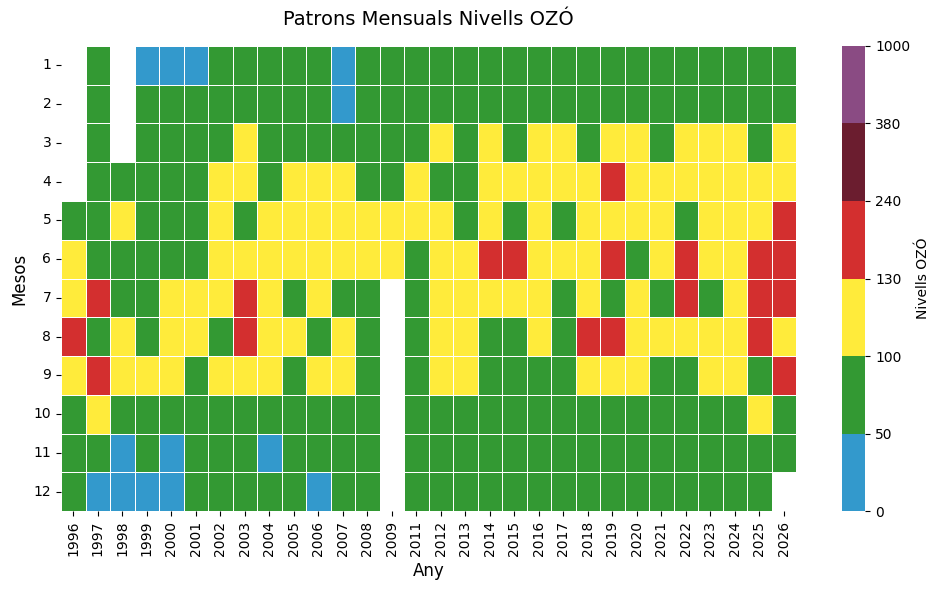

In [113]:
generar_mapa_calor(df_max_mensual, Nom)

### **Quants dies l'any es supera el llindar recomanat?**

##🟢 **Generem dades processades**

In [114]:
df_llarg_export = df_llarg[['CODI EOI','MAGNITUD','DATA','HORA','value']]
df_llarg_export

,CODI EOI,MAGNITUD,DATA,HORA,value
0,8019043,14,1996-05-08,0,13.0
1,8019043,14,1996-05-08,1,33.0
2,8019043,14,1996-05-08,2,45.0
3,8019043,14,1996-05-08,3,44.0
4,8019043,14,1996-05-08,4,37.0
...,...,...,...,...,...
1159075,8298008,14,2026-11-10,19,NaN
1159076,8298008,14,2026-11-10,20,NaN
1159077,8298008,14,2026-11-10,21,NaN
1159078,8298008,14,2026-11-10,22,NaN


In [115]:
columnes_estacio = [
    "CODI EOI",
    "NOM ESTACIO",
    "TIPUS ESTACIO",
    "CODI INE",
    "MUNICIPI",
    "CODI COMARCA",
    "NOM COMARCA",
    "ALTITUD"]

df_estacions_export = df[columnes_estacio].drop_duplicates().reset_index(drop=True)
df_estacions_export

,CODI EOI,NOM ESTACIO,TIPUS ESTACIO,CODI INE,MUNICIPI,CODI COMARCA,NOM COMARCA,ALTITUD
0,8298008,Vic,background,8298,Vic,24,Osona,498
1,8298007,Vic,traffic,8298,Vic,24,Osona,484
2,8112003,Manlleu,background,8112,Manlleu,24,Osona,460
3,8283004,Tona (Zona Esportiva),background,8283,Tona,24,Osona,620
4,8283002,Tona,background,8283,Tona,24,Osona,629
5,8113007,Manresa,traffic,8113,Manresa,7,Bages,238
6,8019043,Barcelona (Eixample),traffic,8019,Barcelona,13,Barcelonès,26


In [116]:
columnes_cont = ['MAGNITUD','CONTAMINANT','UNITATS']
df_contaminants_export = df[columnes_cont].drop_duplicates().reset_index(drop=True).sort_values(by='MAGNITUD')
df_contaminants_export

,MAGNITUD,CONTAMINANT,UNITATS
7,1,SO2,µg/m3
5,3,PS,µg/m3
6,6,CO,mg/m3
3,7,NO,µg/m3
0,8,NO2,µg/m3
9,9,PM2.5,µg/m3
4,10,PM10,µg/m3
1,12,NOX,µg/m3
2,14,O3,µg/m3
8,42,HCT,ppm


In [117]:

# Guardem els fitxers localment en l'entorn de Colab

df_llarg_export.to_csv("registres_qualitat.csv", index=False)
df_estacions_export.to_csv('estacions_qualitat.csv', index=False)
df_contaminants_export.to_csv('variables_qualitat.csv', index=False)
finestres_ozo.to_csv('finestres_ozo.csv', index=False, na_rep="\\N")
print("Fitxers guardats correctament a l'entorn local de Colab!")

Fitxers guardats correctament a l'entorn local de Colab!


In [118]:
print(finestres_ozo.iloc[190])

DATA               1992-10-02 00:00:00
MAX_OZO_8h                         NaN
CODI_INE                          8298
SUPERA_LIMIT_UE                   <NA>
Name: 190, dtype: object
